# Neighborhood distance shifts

This notebook previews figures for the paper submission:

1. **IMDB:** BERT and GPT-2, isolated, Euclidean distance, NN-10  
2. **BeerAdvocate:** class 0 (palate 0.4), BERT and GPT-2, isolated, Euclidean distance, NN-10  
3. **IMDB additional result:** BERT only, template-based, Euclidean distance, NN-10

The notebook expects `neighborhood_figure_data.csv` to be in the same working directory.


In [25]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Figure settings ---
PLOT_STYLE = "line"      # "line" or "bar"
SHOW_SEM = True         # default: no error bars
SHOW_AXIS_LABELS = False # default: no axis titles
SAVE_FIGURES = False
OUTPUT_DIR = Path("figures")

LAYERS = [5, 8, 11, 12]
COLORS = ("tab:blue", "tab:orange")
LINESTYLES = ("-", "--")
MARKERS = ("o", "s")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


In [26]:
from pathlib import Path
import pandas as pd

DATA_FILE = Path("neighborhood_figures_notebook_package/neighborhood_figure_data.csv")

df = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
print(f"Loaded {len(df)} rows from {DATA_FILE.resolve()}")

Loaded 64 rows from /Users/leosteiner/Desktop/transformer-shortcut-mitigation/neighborhood_figures_notebook_package/neighborhood_figure_data.csv


### Optional: replace BeerAdvocate preview rows with exact notebook exports

If available, place `beer_bert_exact.csv` and `beer_gpt2_exact.csv` next to this notebook.  
These files should be exported from the BeerAdvocate source notebooks after `matched_anchor_summary_df` is constructed:

```python
matched_anchor_summary_df.to_csv('beer_bert_exact.csv', index=False)
matched_anchor_summary_df.to_csv('beer_gpt2_exact.csv', index=False)
```


In [27]:
def insert_exact_beer_data(df, path, model):
    if not path.exists():
        return df
    exact = pd.read_csv(path, dtype=str, keep_default_na=False)
    required = {
        "predicted_class", "context", "k", "anchor_layer", "layer",
        "group", "n_patterns", "mean_delta_euclidean", "sem_delta_euclidean"
    }
    if not required.issubset(exact.columns):
        raise ValueError(f"{path}: missing columns {sorted(required - set(exact.columns))}")

    subset = exact.loc[
        (exact["predicted_class"] == "0") &
        (exact["context"] == "iso") &
        (exact["k"] == "10") &
        (exact["anchor_layer"] == exact["layer"]) &
        (exact["group"].isin(["listed_candidate", "other_pattern"]))
    ]

    observed = {(int(r.layer), r.group) for r in subset.itertuples()}
    wanted = {(layer, group) for layer in LAYERS for group in ["listed_candidate", "other_pattern"]}
    if observed != wanted or len(subset) != 8:
        raise ValueError(
            f"{path}: expected 8 complete class-0 isolated NN-10 rows; "
            "export the full DataFrame, not the truncated notebook display"
        )

    out = df.copy()
    for r in subset.itertuples():
        match = (
            (out["dataset"] == "BeerAdvocate") &
            (out["model"] == model) &
            (out["context"] == "iso") &
            (out["predicted_class"] == "0") &
            (out["k"] == "10") &
            (out["layer"] == str(r.layer)) &
            (out["group"] == r.group)
        )
        if match.sum() != 1:
            raise ValueError(f"Expected one row to replace: {model}, L{r.layer}, {r.group}")
        out.loc[match, [
            "mean_delta_euclidean", "sem_delta_euclidean", "n_patterns", "data_quality"
        ]] = [r.mean_delta_euclidean, r.sem_delta_euclidean, r.n_patterns, "exact_notebook_export"]

    print(f"Replaced 8 rows using {path.name}")
    return out

for model, filename in [("BERT", "beer_bert_exact.csv"), ("GPT-2", "beer_gpt2_exact.csv")]:
    df = insert_exact_beer_data(df, Path(filename), model)


In [30]:
GROUPS = {
    "IMDB": [("numeric", "Numerical patterns"),
             ("non_numeric", "Other patterns")],
    "BeerAdvocate": [("listed_candidate", "Listed candidates"),
                      ("other_pattern", "Other mined patterns")],
}


def get_series(dataset, model, context, class_id="", k=10):
    series = {}
    for group, label in GROUPS[dataset]:
        sub = df.loc[
            (df["dataset"] == dataset) &
            (df["model"] == model) &
            (df["context"] == context) &
            (df["k"] == str(k)) &
            (df["group"] == group)
        ].copy()
        sub["layer"] = sub["layer"].astype(int)
        sub = sub.set_index("layer").reindex(LAYERS)
        if sub["mean_delta_euclidean"].isna().any():
            raise ValueError(f"Missing layers for {dataset}, {model}, {context}, {group}")
        series[group] = (
            sub["mean_delta_euclidean"].astype(float).to_numpy(),
            sub["sem_delta_euclidean"].astype(float).to_numpy()
        )
    return series


def plot_panel(ax, dataset, model, context="iso", class_id="", k=10):
    series = get_series(dataset, model, context, class_id, k)
    for i, (group, label) in enumerate(GROUPS[dataset]):
        mean, sem = series[group]
        if PLOT_STYLE == "line":
            if SHOW_SEM:
                ax.errorbar(
                    LAYERS, mean, yerr=sem,
                    marker=MARKERS[i], linestyle=LINESTYLES[i],
                    color=COLORS[i], linewidth=2.0, markersize=5,
                    capsize=3, elinewidth=1, label=label
                )
            else:
                ax.plot(
                    LAYERS, mean,
                    marker=MARKERS[i], linestyle=LINESTYLES[i],
                    color=COLORS[i], linewidth=2.0, markersize=5,
                    label=label
                )
        elif PLOT_STYLE == "bar":
            import numpy as np
            width = 0.35
            x = np.arange(len(LAYERS)) + (i - 0.5) * width
            ax.bar(
                x, mean, width,
                yerr=sem if SHOW_SEM else None,
                color=COLORS[i], capsize=3 if SHOW_SEM else 0,
                label=label
            )
            ax.set_xticks(range(len(LAYERS)), [f"L{l}" for l in LAYERS])
        else:
            raise ValueError("PLOT_STYLE must be 'line' or 'bar'")

    if PLOT_STYLE == "line":
        ax.set_xticks(LAYERS, [f"L{l}" for l in LAYERS])
        ax.set_xlim(4.4, 12.6)

    ax.set_ylim(bottom=0)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="y", which="both", left=False, labelleft=False)
    ax.set_title(model, fontsize=11)
    if SHOW_AXIS_LABELS:
        ax.set_xlabel("Transformer layer")
    ax.grid(axis="y", linewidth=0.5, alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.legend(fontsize=8, frameon=False, loc="upper left")


def show_figure(stem, dataset, panels, caption=""):
    fig, axs = plt.subplots(
        1, len(panels),
        figsize=(9.0, 3.5) if len(panels) > 1 else (5.5, 3.5),
        layout="constrained", squeeze=False
    )
    for ax, config in zip(axs[0], panels):
        plot_panel(ax, dataset, **config)
    if SHOW_AXIS_LABELS:
        axs[0][0].set_ylabel("Mean absolute Euclidean distance shift")
    if caption:
        fig.suptitle(caption, fontsize=11)
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
        fig.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
        fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=350, bbox_inches="tight")
        print(f"Saved PDF and PNG to {OUTPUT_DIR / stem}")
    plt.show()


## Figure 1 — IMDB, isolated Euclidean distance

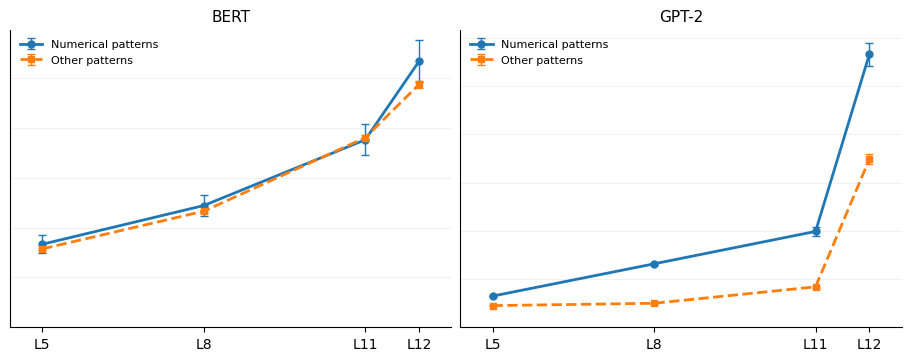

In [31]:
show_figure(
    "fig_imdb_isolated_euclidean",
    "IMDB",
    [
        {"model": "BERT", "context": "iso"},
        {"model": "GPT-2", "context": "iso"},
    ],
)


## Figure 2 — BeerAdvocate, class 0, isolated Euclidean distance, NN-10

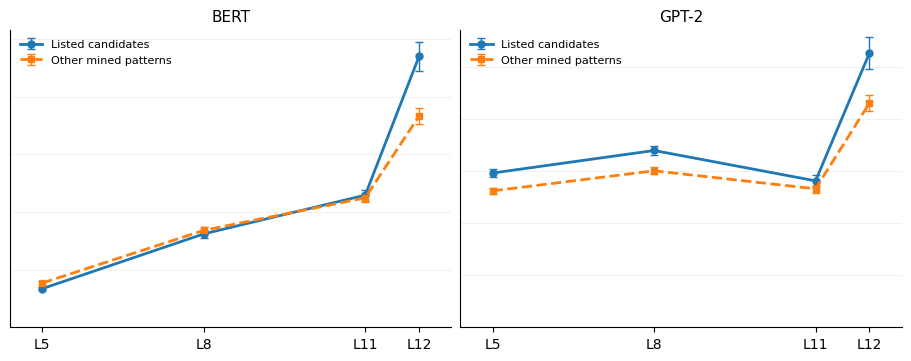

In [32]:
show_figure(
    "fig_beer_class0_isolated_euclidean_nn10",
    "BeerAdvocate",
    [
        {"model": "BERT", "context": "iso", "class_id": "0", "k": 10},
        {"model": "GPT-2", "context": "iso", "class_id": "0", "k": 10},
    ],
)


## Figure 3 — IMDB, BERT only, template-based Euclidean distance

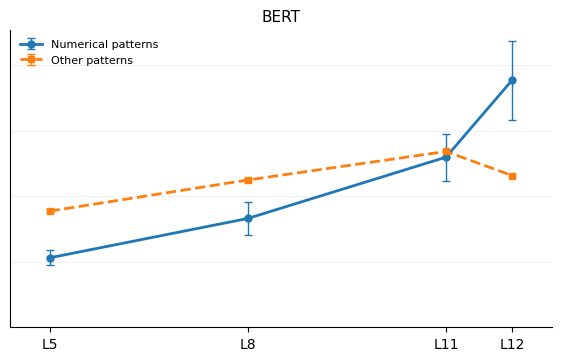

In [24]:
show_figure(
    "fig_imdb_bert_templated_euclidean",
    "IMDB",
    [
        {"model": "BERT", "context": "tpl"},
    ],
)
